# Etapa 4 — Desarrollo de modelos

**Modelo de Machine Learning para el cribado técnico de reservorios candidatos a waterflooding**

Proyecto de titulación — Maestría en Petróleos, ESPOL
En cooperación con EP Petroecuador (Gerencia de Activo Auca)

---

Este cuaderno corresponde a la **Etapa 4** del flujo de trabajo metodológico:

| Paso | Contenido |
|---|---|
| 4.1 | Árbol de decisión como modelo base |
| 4.2 | Random Forest |
| 4.3 | XGBoost |
| 4.4 | SVM |
| 4.5 | Optimización de hiperparámetros mediante validación cruzada estratificada |

**Qué hace y qué no hace esta etapa.** Aquí se construyen los cuatro modelos y se optimizan sus
hiperparámetros usando **solo el conjunto de entrenamiento**. El conjunto de prueba no se toca: la
comparación final, la matriz de confusión y la selección del modelo corresponden a la Etapa 5.

Todo lo que se usa aquí viene fijado por la Etapa 3: la división entrenamiento / prueba, las 5
particiones de validación cruzada, el transformador de escalado y la ponderación de clases.

## 1. Configuración del entorno

In [1]:
import os, sys, subprocess

REPO_URL = "https://github.com/phabelog/waterflooding-ml-screening.git"
REPO_DIR = "waterflooding-ml-screening"

if os.path.isdir("src/models"):
    REPO_ROOT = "."
else:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    else:
        subprocess.run(["git", "-C", REPO_DIR, "pull", "-q"], check=True)
    REPO_ROOT = REPO_DIR

sys.path.insert(0, os.path.join(REPO_ROOT, "src", "models"))
print("Repositorio listo en:", os.path.abspath(REPO_ROOT))

Repositorio listo en: /content/waterflooding-ml-screening


XGBoost debe ser la versión 2.1.4 o posterior para funcionar con las versiones actuales de
scikit-learn. Google Colab ya la trae; la celda siguiente solo lo comprueba.

In [2]:
import sklearn
try:
    import xgboost
    v_xgb = xgboost.__version__
except ImportError:
    v_xgb = None

print("scikit-learn:", sklearn.__version__)
print("xgboost:     ", v_xgb)

def _v(x):
    return tuple(int(p) for p in x.split(".")[:3] if p.isdigit())

if v_xgb is None or _v(v_xgb) < (2, 1, 4):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "xgboost>=2.1.4"], check=True)
    print("\nxgboost se actualizó. Vaya a Entorno de ejecución -> Reiniciar sesión y vuelva a ejecutar todo.")
else:
    print("\nVersiones compatibles.")

scikit-learn: 1.6.1
xgboost:      3.4.1

Versiones compatibles.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import train_models as tm
import preprocess as pp

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
AZUL, ROJO, GRIS = "#1f4e79", "#c0392b", "#7f7f7f"

df = pd.read_csv(os.path.join(REPO_ROOT, "data", "synthetic", "synthetic_dataset.csv"))

---
## 2. Punto de partida: lo que fija la Etapa 3

In [4]:
X_train, X_test, y_train, y_test = pp.split_train_test(df)
des = pp.resampling_decision(y_train)

p = y_train.mean()
F1_TRIVIAL = 2 * p / (1 + p)

print(f"Entrenamiento: {len(X_train)} escenarios ({p*100:.1f} % aptos)")
print(f"Prueba:        {len(X_test)} escenarios  -> RETENIDO, no se usa en esta etapa")
print(f"Validación cruzada: {pp.CV_FOLDS} particiones estratificadas (semilla {pp.RANDOM_STATE})")
print(f"Ponderación: class_weight='balanced' | scale_pos_weight = {des['scale_pos_weight']:.3f}")
print()
print(f"Referencia trivial: declarar 'apto' a todos los casos da F1 = {F1_TRIVIAL:.3f}")

Entrenamiento: 4000 escenarios (38.9 % aptos)
Prueba:        1000 escenarios  -> RETENIDO, no se usa en esta etapa
Validación cruzada: 5 particiones estratificadas (semilla 42)
Ponderación: class_weight='balanced' | scale_pos_weight = 1.569

Referencia trivial: declarar 'apto' a todos los casos da F1 = 0.560


La referencia trivial sirve de piso: cualquier modelo útil debe superarla con amplitud. El
**árbol de decisión** cumple el papel de **modelo base** de la metodología: es el más simple e
interpretable de los cuatro, y los modelos más complejos solo se justifican si lo superan.

### Métrica de optimización

Se optimiza **F1**, la media armónica entre precisión y recall. En el cribado hay dos errores con
costo: recomendar un reservorio inviable (falso positivo, baja la precisión) y descartar un buen
candidato (falso negativo, baja el recall). F1 penaliza ambos a la vez. Se registran también la
precisión, el recall y la exactitud (*accuracy*), conforme al objetivo específico 4 del
anteproyecto.

---
## 3. Pasos 4.1 a 4.4 — Los cuatro modelos y sus grillas

Cada modelo es un *pipeline* con dos pasos: el transformador de escalado de la Etapa 3 y el
clasificador. Así, dentro de la validación cruzada, el escalado se ajusta solo con la parte de
ajuste de cada partición.

| Modelo | Por qué se incluye |
|---|---|
| Árbol de decisión | Modelo base: simple, interpretable, reglas de corte similares al cribado tradicional |
| Random Forest | Promedia muchos árboles para reducir la varianza de un árbol único |
| XGBoost | Construye árboles en secuencia, cada uno corrigiendo los errores del anterior |
| SVM | Enfoque distinto, no basado en árboles: frontera de decisión suave mediante núcleo RBF |

Las grillas son deliberadamente acotadas: cubren los hiperparámetros que controlan la complejidad
de cada modelo, con valores habituales, sin multiplicar el tiempo de cómputo.

In [5]:
filas = []
for m in tm.MODEL_NAMES:
    g = tm.PARAM_GRIDS[m]
    for k, v in g.items():
        filas.append({"modelo": tm.MODEL_LABELS[m], "hiperparámetro": k.replace("clf__", ""),
                      "valores": ", ".join(str(x) for x in v)})
    print(f"{tm.MODEL_LABELS[m]:26s} {int(np.prod([len(v) for v in g.values()])):2d} combinaciones")
pd.DataFrame(filas).set_index(["modelo", "hiperparámetro"])

Árbol de decisión (base)   15 combinaciones
Random Forest               6 combinaciones
XGBoost                    12 combinaciones
SVM                         9 combinaciones


valores
modelo                   hiperparámetro                      
Árbol de decisión (base) max_depth         5, 8, 12, 16, None
                         min_samples_leaf           5, 20, 50
Random Forest            min_samples_leaf                1, 3
                         max_features          sqrt, 0.5, 0.8
XGBoost                  n_estimators                300, 600
                         max_depth                    3, 5, 7
                         learning_rate              0.05, 0.1
SVM                      C                      10, 100, 1000
                         gamma              0.005, 0.01, 0.02

---
## 4. Paso 4.5 — Optimización con validación cruzada estratificada

Cada combinación se evalúa en las 5 particiones: se ajusta con 4/5 del entrenamiento y se mide en el
quinto restante. La métrica reportada es el promedio de las 5 mediciones, con su desviación
estándar. **Tarda entre 3 y 5 minutos en Colab.**

In [6]:
resumen, mejores, busquedas = tm.run_all(df)

Árbol de decisión (base)   15 combinaciones x 5 particiones ... F1 = 0.9124  (11 s)
Random Forest               6 combinaciones x 5 particiones ... F1 = 0.9317  (219 s)
XGBoost                    12 combinaciones x 5 particiones ... F1 = 0.9526  (45 s)
SVM                         9 combinaciones x 5 particiones ... F1 = 0.8392  (56 s)


In [7]:
tabla = resumen[["etiqueta", "f1_media", "f1_desv", "precision_media", "recall_media",
                  "accuracy_media", "combinaciones", "tiempo_s"]].copy()
tabla.columns = ["Modelo", "F1", "F1 desv.", "Precisión", "Recall", "Exactitud",
                 "Combinaciones", "Tiempo (s)"]
tabla.round(4)

,Modelo,F1,F1 desv.,Precisión,Recall,Exactitud,Combinaciones,Tiempo (s)
modelo,,,,,,,,
arbol_decision,Árbol de decisión (base),0.9124,0.0138,0.8848,0.9422,0.9295,15,10.8
random_forest,Random Forest,0.9317,0.0107,0.9221,0.9415,0.9462,6,218.8
xgboost,XGBoost,0.9526,0.0083,0.9384,0.9672,0.9625,12,44.6
svm,SVM,0.8392,0.0080,0.8083,0.8728,0.8698,9,55.7


In [8]:
print("Mejores hiperparámetros:")
for m in tm.MODEL_NAMES:
    print(f"   {tm.MODEL_LABELS[m]:26s} {mejores[m]}")

Mejores hiperparámetros:
   Árbol de decisión (base)   {'max_depth': 12, 'min_samples_leaf': 20}
   Random Forest              {'max_features': 0.8, 'min_samples_leaf': 1}
   XGBoost                    {'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 600}
   SVM                        {'C': 100, 'gamma': 0.01}


---
## 5. Análisis de los resultados de validación cruzada

### 5.1 Desempeño comparado

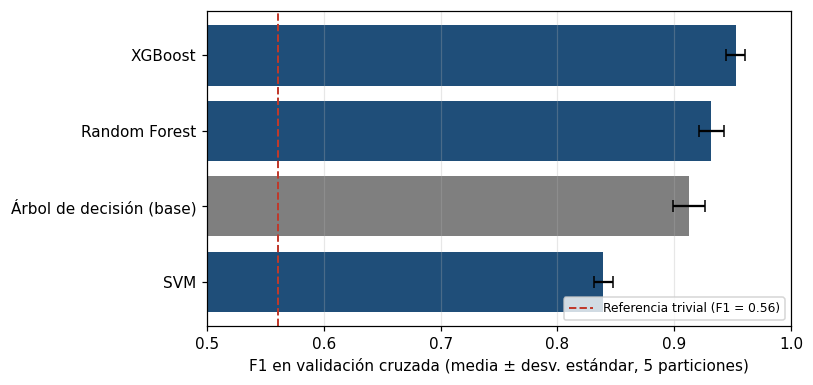

In [9]:
orden = resumen.sort_values("f1_media")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
colores = [GRIS if m == "arbol_decision" else AZUL for m in orden.index]
ax.barh(orden["etiqueta"], orden["f1_media"], xerr=orden["f1_desv"], color=colores, capsize=4)
ax.axvline(F1_TRIVIAL, ls="--", color=ROJO, lw=1.3, label=f"Referencia trivial (F1 = {F1_TRIVIAL:.2f})")
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("F1 en validación cruzada (media ± desv. estándar, 5 particiones)")
ax.legend(loc="lower right", fontsize=8); ax.grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()

Una diferencia entre dos modelos solo es relevante si supera la variabilidad entre particiones.
Como regla práctica, diferencias menores que una desviación estándar no permiten preferir un modelo
sobre otro con base en este resultado.

### 5.2 Sobreajuste: entrenamiento frente a validación

La brecha entre el F1 en los datos de ajuste y el F1 en validación indica cuánto memoriza cada
modelo. En Random Forest un F1 de entrenamiento cercano a 1 es normal (los árboles crecen hasta
separar los datos de ajuste) y no implica un problema: lo que importa es su F1 en validación.

In [10]:
sob = resumen[["etiqueta", "f1_entrenamiento", "f1_media", "brecha_f1"]].copy()
sob.columns = ["Modelo", "F1 ajuste", "F1 validación", "Brecha"]
sob.round(4)

,Modelo,F1 ajuste,F1 validación,Brecha
modelo,,,,
arbol_decision,Árbol de decisión (base),0.9348,0.9124,0.0223
random_forest,Random Forest,1.0000,0.9317,0.0683
xgboost,XGBoost,1.0000,0.9526,0.0474
svm,SVM,0.9116,0.8392,0.0724


### 5.3 Estabilidad frente a los hiperparámetros

Si muchas combinaciones de la grilla quedan a menos de una desviación estándar de la mejor, el
desempeño del modelo no depende de un ajuste fino: es robusto a la elección de hiperparámetros.

In [11]:
filas = []
for m in tm.MODEL_NAMES:
    cv = busquedas[m].cv_results_
    f1 = cv["mean_test_f1"]
    mejor, desv = resumen.loc[m, "f1_media"], resumen.loc[m, "f1_desv"]
    filas.append({"Modelo": tm.MODEL_LABELS[m],
                  "F1 mejor": mejor, "F1 peor": f1.min(),
                  "Combinaciones a < 1 desv. de la mejor": f"{int((f1 >= mejor - desv).sum())} de {len(f1)}"})
pd.DataFrame(filas).set_index("Modelo").round(4)

,F1 mejor,F1 peor,Combinaciones a < 1 desv. de la mejor
Modelo,,,
Árbol de decisión (base),0.9124,0.8968,13 de 15
Random Forest,0.9317,0.9173,4 de 6
XGBoost,0.9526,0.9377,11 de 12
SVM,0.8392,0.8043,5 de 9


---
## 6. Guardado de los resultados para la Etapa 5

Se guardan los mejores hiperparámetros y las métricas de validación cruzada en
`results/etapa4_resultados.json`. La Etapa 5 reconstruirá cada modelo con esos hiperparámetros, lo
ajustará con todo el entrenamiento y lo evaluará **una sola vez** sobre el conjunto de prueba.

En Colab, la última celda descarga el archivo a su computadora para subirlo luego al repositorio, en
la carpeta `results/`.

In [12]:
ruta = tm.save_results(resumen, mejores, os.path.join(REPO_ROOT, "results", "etapa4_resultados.json"))
print("Guardado en:", ruta)

try:
    from google.colab import files
    files.download(ruta)
except ImportError:
    pass   # fuera de Colab el archivo ya queda en la carpeta results/

Guardado en: waterflooding-ml-screening/results/etapa4_resultados.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 7. Conclusiones de la Etapa 4

- Los cuatro modelos de la metodología quedaron construidos sobre la misma base: el transformador de
  escalado, las particiones y la ponderación de clases definidos en la Etapa 3.
- Sus hiperparámetros se optimizaron por F1 mediante validación cruzada estratificada de 5
  particiones, usando exclusivamente el conjunto de entrenamiento.
- La tabla de la sección 4 y la figura de la sección 5.1 muestran el desempeño de cada uno en
  validación cruzada; la sección 5.2 cuantifica su sobreajuste y la 5.3 su sensibilidad a los
  hiperparámetros.
- **No se selecciona aquí el modelo final.** El ordenamiento en validación cruzada es una primera
  señal, pero la comparación definitiva se hace en la Etapa 5 sobre el conjunto de prueba retenido,
  junto con la matriz de confusión, la interpretación del modelo y la comparación con el cribado
  tradicional.

---
### Siguiente paso del flujo de trabajo

**Etapa 5 — Evaluación y validación de modelos:** métricas sobre el conjunto de prueba, matriz de
confusión, selección del modelo final, interpretación e importancia de variables (incluidos los
controles negativos), comparación con el cribado tradicional y, cuando se reciban los datos de EP
Petroecuador, validación externa.

Cuaderno siguiente: `05_evaluacion_validacion.ipynb`